In [1]:
!pip install ultralytics opencv-python numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 9.6 MB/s eta 0:00:00


In [2]:
from google.colab import files
uploaded = files.upload()
video_path = list(uploaded.keys())[0]
print("Uploaded:", video_path)

Saving barcamatch.mp4 to barcamatch.mp4
Uploaded: barcamatch.mp4


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Size: 1920x1080, FPS: 30.0, Frames: 1558, Length: 51.9s


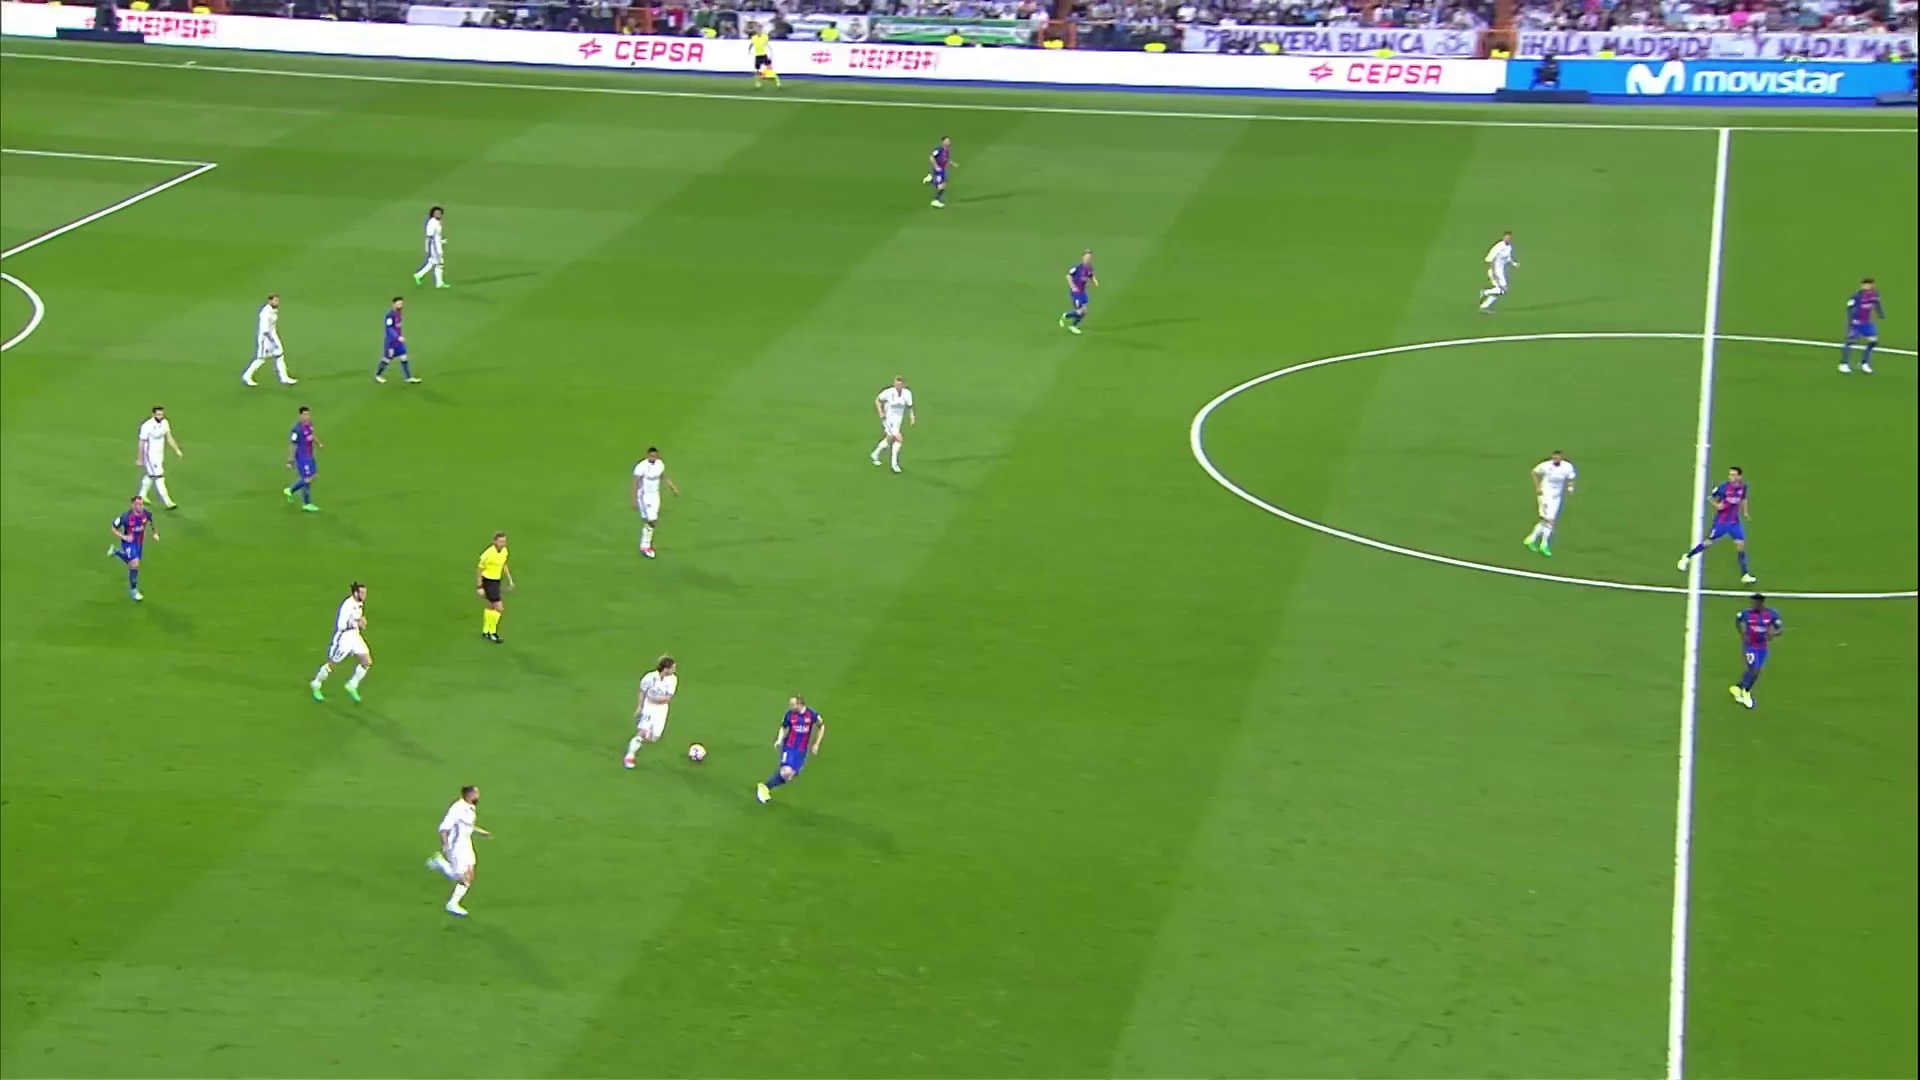

True

In [3]:
from ultralytics import YOLO
import cv2, numpy as np
from collections import deque
from google.colab.patches import cv2_imshow

model = YOLO("yolo11l.pt")          # downloads automatically the first time
cap = cv2.VideoCapture(video_path)

w, h = int(cap.get(3)), int(cap.get(4))
fps = cap.get(5)
total = int(cap.get(7))
print(f"Size: {w}x{h}, FPS: {fps:.1f}, Frames: {total}, Length: {total/fps:.1f}s")

out = cv2.VideoWriter("output.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

# show the first frame as a sanity check
ok, frame = cap.read()
cv2_imshow(frame)
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)   # rewind to the start

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 314ms
Prepared 1 package in 54ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

People: 20 | Balls: 1


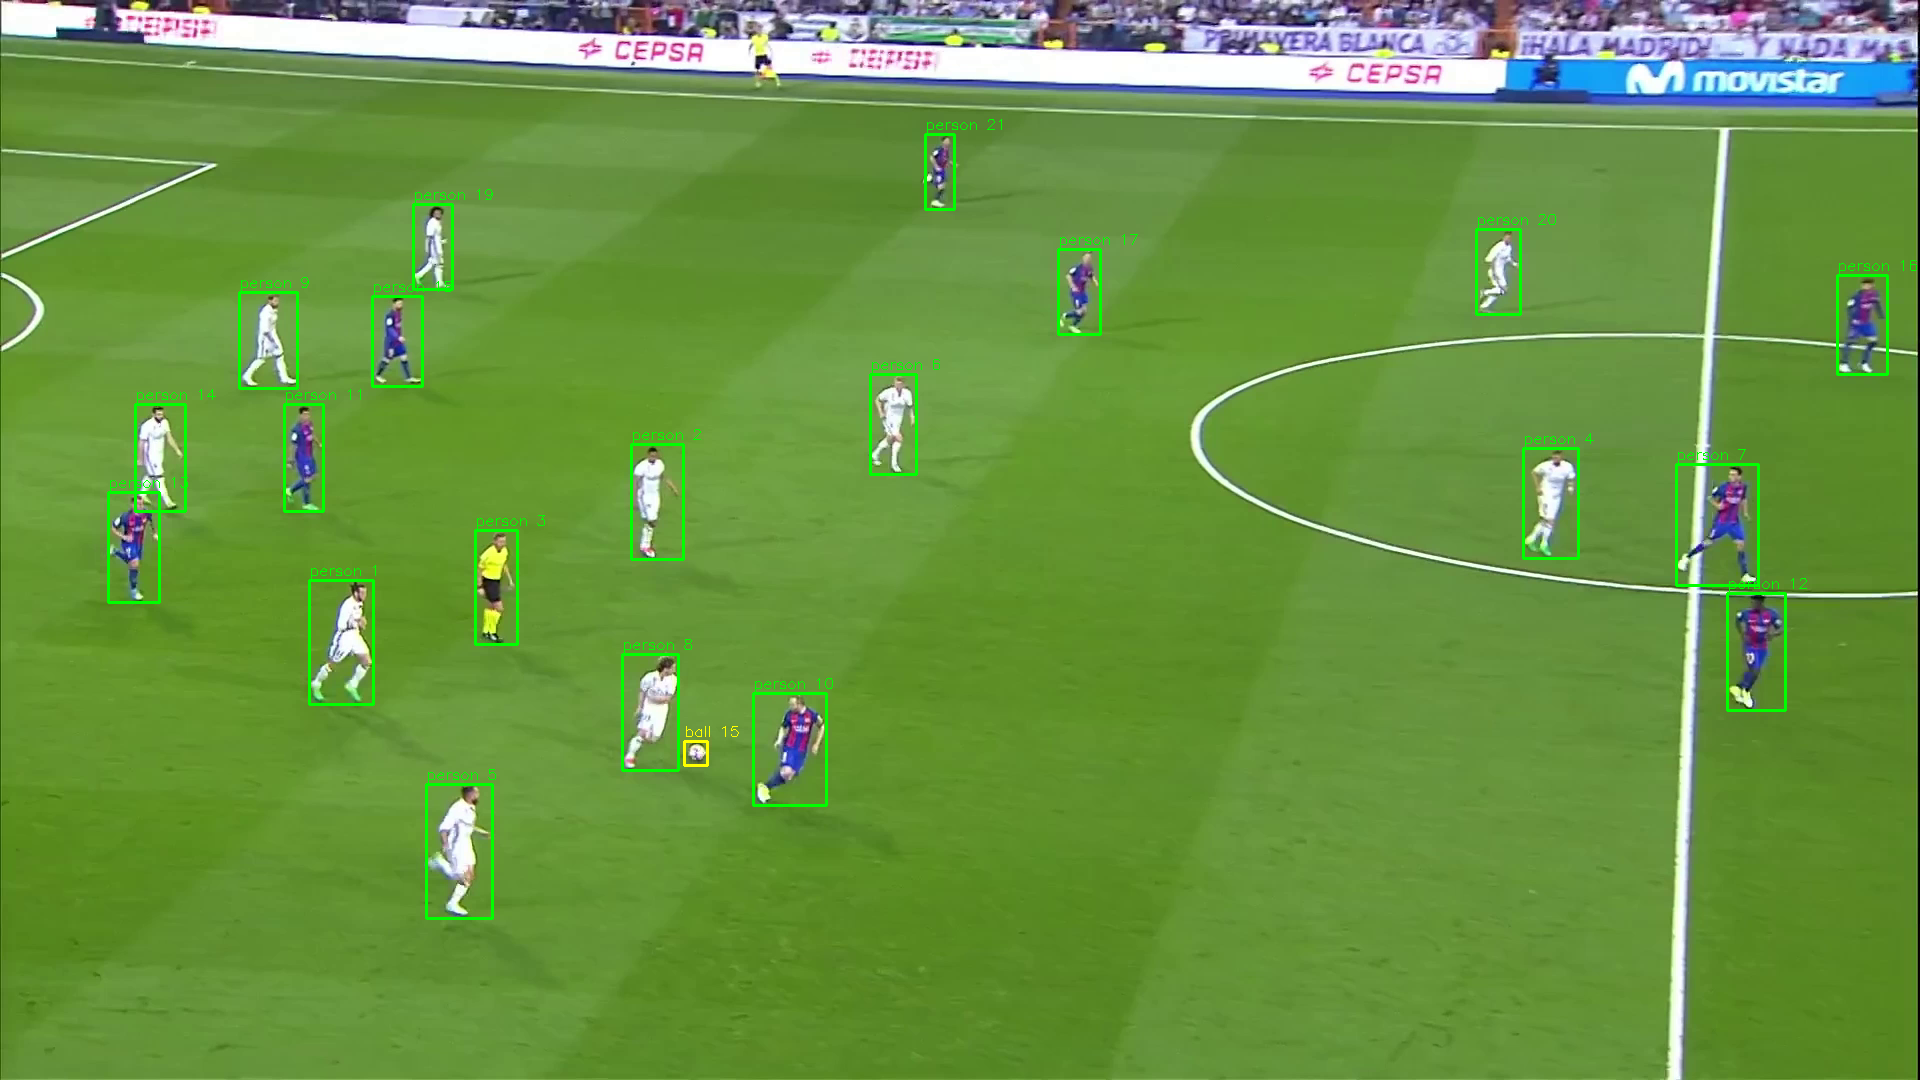

In [4]:
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
ok, frame = cap.read()

results = model.track(frame, persist=True, tracker="bytetrack.yaml",
                      classes=[0, 32], conf=0.25, verbose=False)[0]

preview = frame.copy()
for box in results.boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0])
    cls = int(box.cls[0])
    tid = int(box.id[0]) if box.id is not None else -1
    color = (0, 255, 255) if cls == 32 else (0, 255, 0)
    cv2.rectangle(preview, (x1, y1), (x2, y2), color, 2)
    cv2.putText(preview, f"{'ball' if cls == 32 else 'person'} {tid}",
                (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

print("People:", sum(int(b.cls[0]) == 0 for b in results.boxes),
      "| Balls:", sum(int(b.cls[0]) == 32 for b in results.boxes))
cv2_imshow(preview)

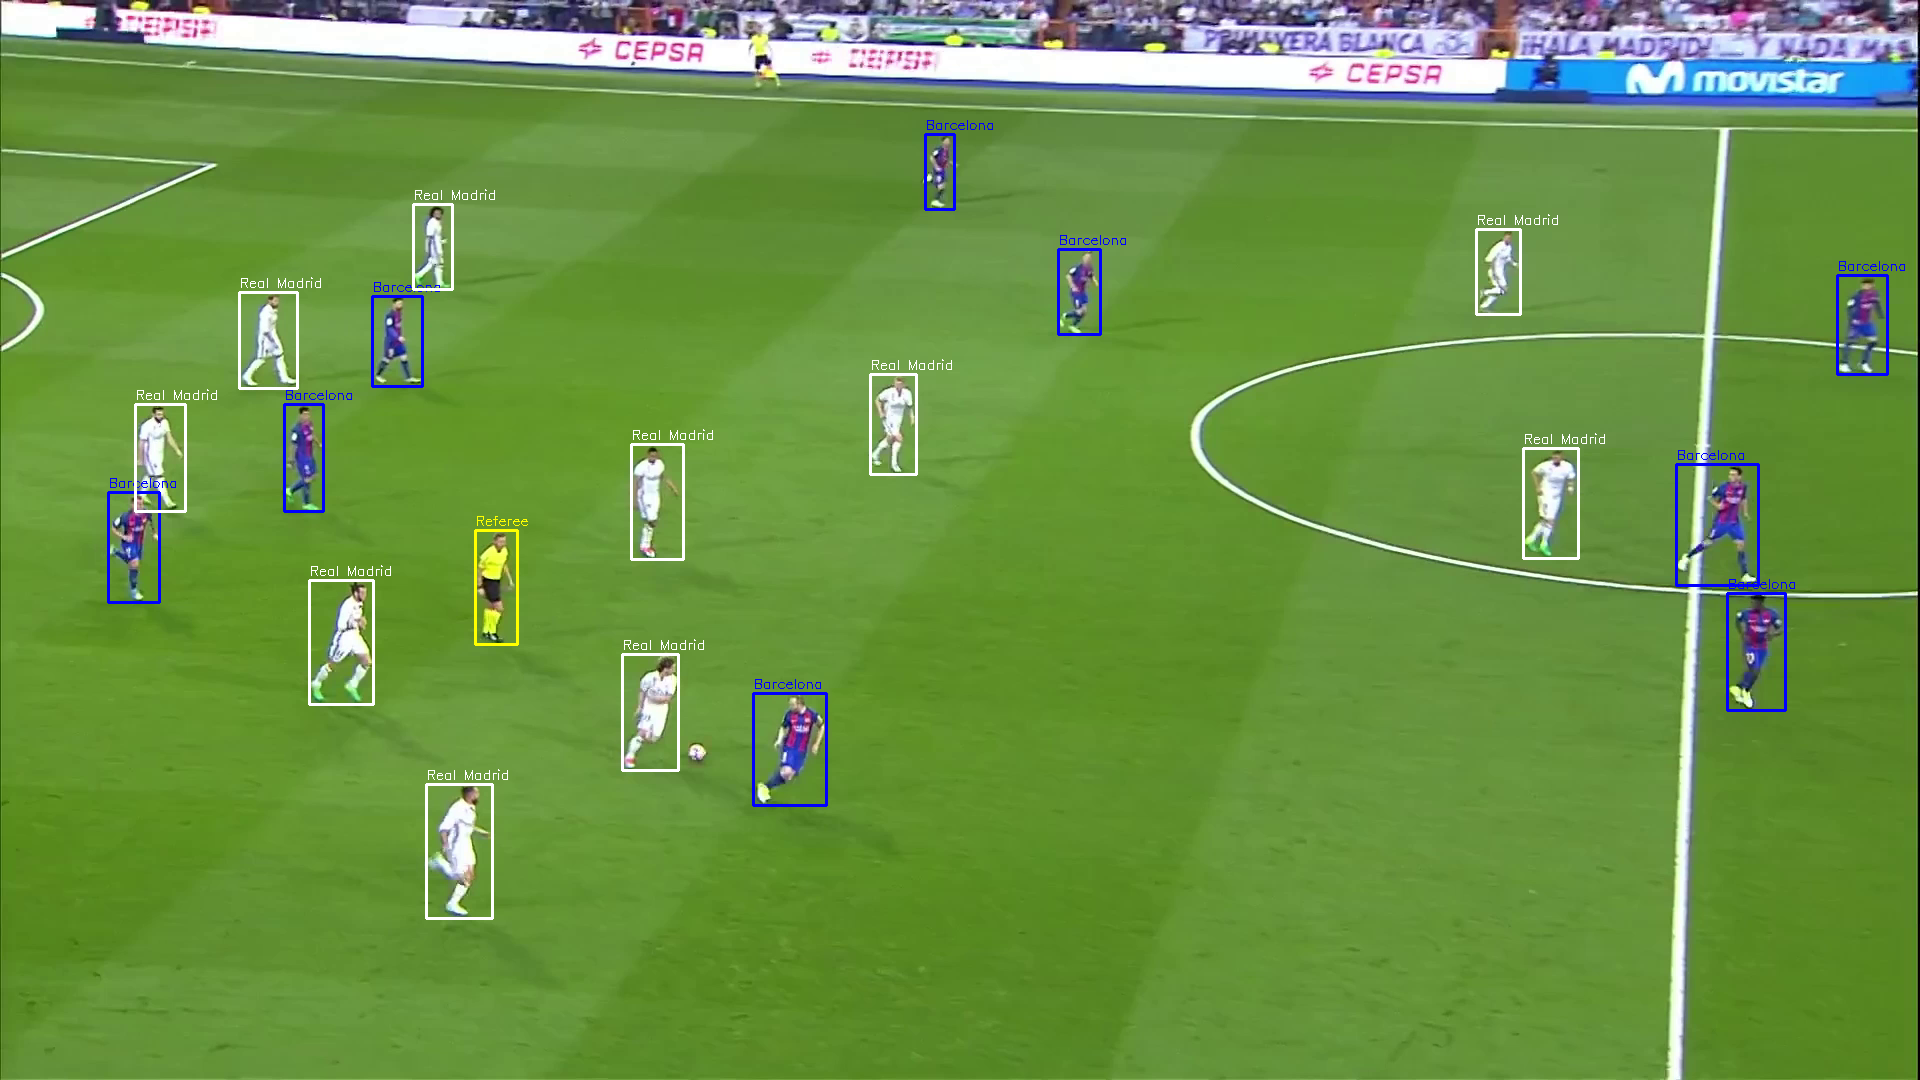

In [5]:
def get_team(frame, box):
    x1, y1, x2, y2 = map(int, box)
    torso = frame[y1 + (y2-y1)//5 : y1 + (y2-y1)//2, x1:x2]
    if torso.size == 0:
        return "Unknown"
    hsv = cv2.cvtColor(torso, cv2.COLOR_BGR2HSV)
    total = torso.shape[0] * torso.shape[1]

    white  = cv2.countNonZero(cv2.inRange(hsv, (0, 0, 170),   (180, 50, 255))) / total
    yellow = cv2.countNonZero(cv2.inRange(hsv, (20, 100, 120), (35, 255, 255))) / total

    if yellow > 0.25:
        return "Referee"
    if white > 0.25:
        return "Real Madrid"
    return "Barcelona"

team_colors = {"Barcelona": (255, 0, 0), "Real Madrid": (255, 255, 255),
               "Referee": (0, 255, 255), "Unknown": (128, 128, 128)}

preview = frame.copy()
for box in results.boxes:
    if int(box.cls[0]) != 0:
        continue
    x1, y1, x2, y2 = map(int, box.xyxy[0])
    team = get_team(frame, (x1, y1, x2, y2))
    cv2.rectangle(preview, (x1, y1), (x2, y2), team_colors[team], 2)
    cv2.putText(preview, team, (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.45, team_colors[team], 1)
cv2_imshow(preview)

In [6]:
from ultralytics import YOLO
import cv2, numpy as np, glob
from collections import deque, Counter
from google.colab.patches import cv2_imshow

# find your uploaded clip (ignores the files we create)
clips = [f for f in glob.glob("/content/*.mp4") if "output" not in f]
print("Found clips:", clips)
video_path = clips[0]

model = YOLO("yolo11l.pt")
cap = cv2.VideoCapture(video_path)
w, h = int(cap.get(3)), int(cap.get(4))
fps = cap.get(5)
total = int(cap.get(7))
print(f"Size: {w}x{h}, FPS: {fps:.1f}, Frames: {total}, Length: {total/fps:.1f}s")

def get_team(frame, box):
    x1, y1, x2, y2 = map(int, box)
    torso = frame[y1 + (y2-y1)//5 : y1 + (y2-y1)//2, x1:x2]
    if torso.size == 0:
        return "Unknown"
    hsv = cv2.cvtColor(torso, cv2.COLOR_BGR2HSV)
    total_px = torso.shape[0] * torso.shape[1]

    white  = cv2.countNonZero(cv2.inRange(hsv, (0, 0, 170),   (180, 50, 255))) / total_px
    yellow = cv2.countNonZero(cv2.inRange(hsv, (20, 100, 120), (35, 255, 255))) / total_px

    if yellow > 0.25:
        return "Referee"
    if white > 0.25:
        return "Real Madrid"
    return "Barcelona"

Found clips: ['/content/barcamatch.mp4']
Size: 1920x1080, FPS: 30.0, Frames: 1558, Length: 51.9s


In [7]:
from collections import deque, Counter

# fresh model so the tracker starts clean, and rewind the video
model = YOLO("yolo11l.pt")
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
out = cv2.VideoWriter("output.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

def on_pitch(frame, box):
    x1, y1, x2, y2 = map(int, box)
    cx = (x1 + x2) // 2
    patch = frame[max(y2-6, 0):y2+6, max(cx-15, 0):cx+15]
    if patch.size == 0:
        return False
    hsv = cv2.cvtColor(patch, cv2.COLOR_BGR2HSV)
    green = cv2.inRange(hsv, (35, 40, 40), (85, 255, 255))
    return green.mean() / 255 > 0.4

team_colors = {"Barcelona": (255, 0, 0), "Real Madrid": (255, 255, 255),
               "Referee": (0, 255, 255), "Unknown": (128, 128, 128)}

team_votes = {}                    # player ID -> last 30 team guesses
ball_trail = deque(maxlen=25)      # recent ball positions

frame_no = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break

    result = model.track(frame, persist=True, tracker="bytetrack.yaml",
                         classes=[0, 32], conf=0.25, verbose=False)[0]

    best_ball = None
    for box in result.boxes:
        cls = int(box.cls[0])
        x1, y1, x2, y2 = map(int, box.xyxy[0])

        if cls == 32:                                  # the ball
            conf = float(box.conf[0])
            if best_ball is None or conf > best_ball[0]:
                best_ball = (conf, (x1 + x2) // 2, (y1 + y2) // 2)
            continue

        if box.id is None or not on_pitch(frame, (x1, y1, x2, y2)):
            continue                                   # skip staff and untracked boxes
        tid = int(box.id[0])

        # team guess, smoothed over the last 30 frames
        team_votes.setdefault(tid, deque(maxlen=30)).append(get_team(frame, (x1, y1, x2, y2)))
        team = Counter(team_votes[tid]).most_common(1)[0][0]
        color = team_colors[team]

        # ground marker at the feet + label
        cx, foot_y = (x1 + x2) // 2, y2
        cv2.ellipse(frame, (cx, foot_y), (max((x2 - x1) // 2, 8), 6), 0, -45, 235, color, 2)
        cv2.putText(frame, f"#{tid}", (cx - 10, foot_y + 18),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1)

    # ball trail: newer points are bigger and brighter
    if best_ball is not None:
        ball_trail.append((best_ball[1], best_ball[2]))
    elif ball_trail:
        ball_trail.popleft()                           # trail fades when ball is lost
    for i, p in enumerate(ball_trail):
        cv2.circle(frame, p, 2 + i // 5, (0, 200, 255), -1)

    out.write(frame)
    frame_no += 1
    if frame_no % 50 == 0:
        print(f"Processed {frame_no}/{total} frames")

cap.release()
out.release()
print("Done! Saved output.mp4")

Processed 50/1558 frames
Processed 100/1558 frames
Processed 150/1558 frames
Processed 200/1558 frames
Processed 250/1558 frames
Processed 300/1558 frames
Processed 350/1558 frames
Processed 400/1558 frames
Processed 450/1558 frames
Processed 500/1558 frames
Processed 550/1558 frames
Processed 600/1558 frames
Processed 650/1558 frames
Processed 700/1558 frames
Processed 750/1558 frames
Processed 800/1558 frames
Processed 850/1558 frames
Processed 900/1558 frames
Processed 950/1558 frames
Processed 1000/1558 frames
Processed 1050/1558 frames
Processed 1100/1558 frames
Processed 1150/1558 frames
Processed 1200/1558 frames
Processed 1250/1558 frames
Processed 1300/1558 frames
Processed 1350/1558 frames
Processed 1400/1558 frames
Processed 1450/1558 frames
Processed 1500/1558 frames
Processed 1550/1558 frames
Done! Saved output.mp4


In [9]:
import os
print("output.mp4:", round(os.path.getsize("output.mp4")/1e6, 1), "MB")
print("Clip length:", round(total/fps, 1), "seconds,", f"{w}x{h}")

output.mp4: 144.2 MB
Clip length: 51.9 seconds, 1920x1080


In [10]:
from google.colab import files
files.download("output.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import glob, subprocess

# find your uploaded clip (ignoring files we created)
clips = [f for f in glob.glob("/content/*.mp4")
         if "output" not in f and "clip_short" not in f]
print("Found:", clips)

subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", clips[0],
                "-ss", "0", "-t", "15", "-vf", "scale=1280:-2",
                "clip_short.mp4"], check=True)
print("Saved clip_short.mp4")

Found: ['/content/barcamatch.mp4']
Saved clip_short.mp4


In [12]:
!ffmpeg -y -loglevel error -i "{video_path}" -ss 0 -t 15 -vf scale=1280:-2 clip_short.mp4

In [13]:
open("bytetrack_football.yaml", "w").write("""tracker_type: bytetrack
track_high_thresh: 0.25
track_low_thresh: 0.1
new_track_thresh: 0.3
track_buffer: 90
match_thresh: 0.85
fuse_score: True
""")

145

In [21]:
from ultralytics import YOLO
import cv2, numpy as np, pandas as pd
from collections import deque, Counter
from google.colab.patches import cv2_imshow

cap = cv2.VideoCapture("clip_short.mp4")
w, h = int(cap.get(3)), int(cap.get(4))
fps = cap.get(5)
out = cv2.VideoWriter("output2.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
model = YOLO("yolo11l.pt")

def get_team(frame, box):
    x1, y1, x2, y2 = map(int, box)
    torso = frame[y1 + (y2-y1)//5 : y1 + (y2-y1)//2, x1:x2]
    if torso.size == 0:
        return "Unknown"
    hsv = cv2.cvtColor(torso, cv2.COLOR_BGR2HSV)
    n = torso.shape[0] * torso.shape[1]
    share = lambda m: cv2.countNonZero(m) / n

    yellow = share(cv2.inRange(hsv, (20, 100, 120), (35, 255, 255)))
    gk     = share(cv2.inRange(hsv, (50, 100, 180), (75, 255, 255)))
    white  = share(cv2.inRange(hsv, (0, 0, 170),    (180, 50, 255)))
    blue   = share(cv2.inRange(hsv, (100, 80, 40),  (130, 255, 255)))
    red    = share(cv2.inRange(hsv, (0, 80, 40),    (10, 255, 255))) + \
             share(cv2.inRange(hsv, (160, 80, 40),  (180, 255, 255)))

    if yellow > 0.12: return "Referee"
    if gk     > 0.15: return "GK"
    if white  > 0.25: return "Real Madrid"
    if blue > 0.45:   return "Unknown"
    if blue + red > 0.06: return "Barcelona"
    return "Unknown"

def on_pitch(frame, box):
    x1, y1, x2, y2 = map(int, box)
    cx = (x1 + x2) // 2
    patch = frame[max(y2-6, 0):y2+6, max(cx-15, 0):cx+15]
    if patch.size == 0: return False
    hsv = cv2.cvtColor(patch, cv2.COLOR_BGR2HSV)
    return cv2.inRange(hsv, (35, 40, 40), (85, 255, 255)).mean() / 255 > 0.4

team_colors = {"Barcelona": (255, 0, 0), "Real Madrid": (255, 255, 255),
               "Referee": (0, 255, 255), "GK": (0, 255, 0)}
team_votes, ball_trail, lost = {}, deque(maxlen=25), 0
records, ball_records, frame_no = [], [], 0      # NEW: the data we save

while True:
    ok, frame = cap.read()
    if not ok: break
    res = model.track(frame, persist=True, tracker="bytetrack_football.yaml",
                      classes=[0, 32], conf=0.1, imgsz=1280, verbose=False)[0]

    best_ball = None
    for box in res.boxes:
        cls, conf = int(box.cls[0]), float(box.conf[0])
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        if cls == 32:
            if best_ball is None or conf > best_ball[0]:
                best_ball = (conf, (x1+x2)//2, (y1+y2)//2)
            continue
        if conf < 0.3 or box.id is None or not on_pitch(frame, (x1, y1, x2, y2)):
            continue
        tid = int(box.id[0])
        team_votes.setdefault(tid, deque(maxlen=30)).append(get_team(frame, (x1, y1, x2, y2)))
        team = Counter(team_votes[tid]).most_common(1)[0][0]
        if team == "Unknown": continue
        color = team_colors[team]
        cx = (x1 + x2) // 2
        records.append((frame_no, tid, team, cx, y2))          # NEW: save feet position
        cv2.ellipse(frame, (cx, y2), (max((x2-x1)//2, 8), 6), 0, -45, 235, color, 2)
        cv2.putText(frame, f"#{tid}", (cx-10, y2+18), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1)

    if best_ball:
        bx, by = best_ball[1], best_ball[2]
        if not ball_trail or np.hypot(bx - ball_trail[-1][0], by - ball_trail[-1][1]) < 150:
            ball_trail.append((bx, by)); lost = 0
            ball_records.append((frame_no, bx, by))             # NEW: save ball position
        else:
            lost += 1
            if lost > 10: ball_trail.clear()
    else:
        lost += 1
        if lost > 5 and ball_trail: ball_trail.popleft()
    for i, p in enumerate(ball_trail):
        cv2.circle(frame, p, 2 + i // 5, (0, 200, 255), -1)

    out.write(frame)
    frame_no += 1

cap.release(); out.release()
pd.DataFrame(records, columns=["frame", "id", "team", "x", "y"]).to_csv("positions.csv", index=False)
pd.DataFrame(ball_records, columns=["frame", "x", "y"]).to_csv("ball.csv", index=False)
print(f"Done! {frame_no} frames, {len(records)} player rows, {len(ball_records)} ball rows")

Done! 450 frames, 6384 player rows, 275 ball rows


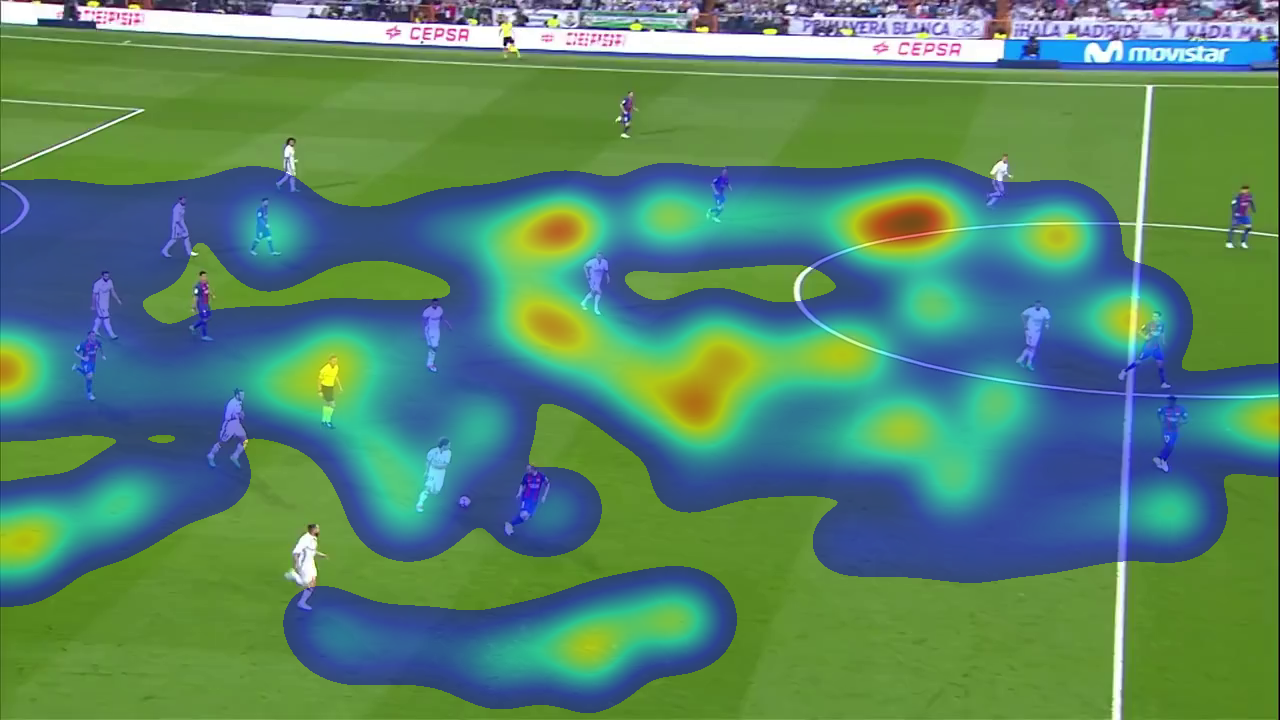

In [22]:
df = pd.read_csv("positions.csv")
team = "Real Madrid"                      # try "Barcelona" too
d = df[df.team == team]

cap2 = cv2.VideoCapture("clip_short.mp4")
ok, bg = cap2.read(); cap2.release()

heat = np.zeros((h, w), np.float32)
for x, y in zip(d.x, d.y):
    if 0 <= x < w and 0 <= y < h:
        heat[y, x] += 1
heat = cv2.GaussianBlur(heat, (0, 0), 25)          # spread each dot into a soft blob
heat = heat / heat.max()

color = cv2.applyColorMap((heat * 255).astype(np.uint8), cv2.COLORMAP_JET)
mask = (heat > 0.05)[..., None]                    # hide the near-zero areas
overlay = np.where(mask, cv2.addWeighted(bg, 0.5, color, 0.5, 0), bg)
cv2_imshow(overlay)

Ball + a nearby player found in 242 of 444 frames
Real Madrid: 56%   Barcelona: 44%


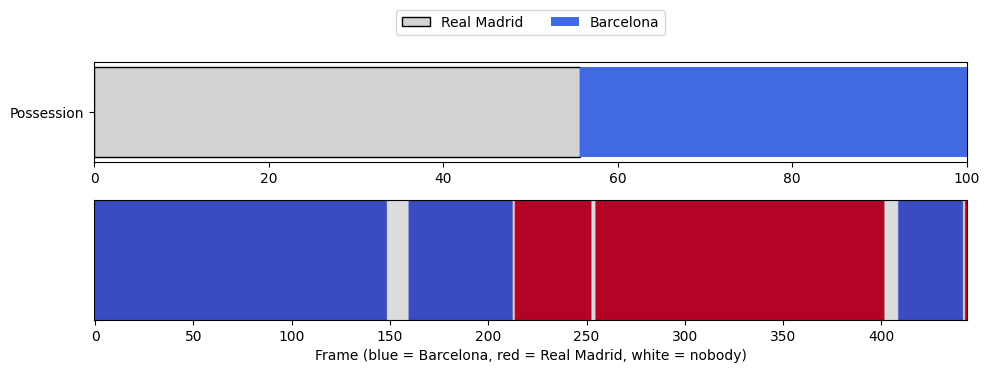

In [23]:
import matplotlib.pyplot as plt

pos  = pd.read_csv("positions.csv")
ball = pd.read_csv("ball.csv")
players = pos[pos.team.isin(["Barcelona", "Real Madrid"])]

MAX_DIST = 120          # pixels: farther than this = nobody has the ball
score = {"Real Madrid": 1, "Barcelona": -1}
vals = pd.Series(np.nan, index=range(int(ball.frame.max()) + 1))

for f, bx, by in ball.itertuples(index=False):
    p = players[players.frame == f]
    if p.empty:
        continue
    d = np.hypot(p.x - bx, p.y - by)
    if d.min() < MAX_DIST:
        vals[f] = score[p.loc[d.idxmin(), "team"]]

# smooth over ~1 second so possession doesn't flicker frame to frame
smooth = vals.rolling(30, min_periods=1, center=True).mean()
madrid = (smooth > 0).sum()
barca  = (smooth < 0).sum()
total  = madrid + barca
print(f"Ball + a nearby player found in {vals.notna().sum()} of {len(vals)} frames")
print(f"Real Madrid: {100*madrid/total:.0f}%   Barcelona: {100*barca/total:.0f}%")

fig, ax = plt.subplots(2, 1, figsize=(10, 4), gridspec_kw={"height_ratios": [1, 1.2]})
ax[0].barh(["Possession"], [madrid/total*100], color="lightgrey", edgecolor="k", label="Real Madrid")
ax[0].barh(["Possession"], [barca/total*100], left=[madrid/total*100], color="royalblue", label="Barcelona")
ax[0].set_xlim(0, 100); ax[0].legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.6))
ax[1].imshow([np.sign(smooth.fillna(0)).values], aspect="auto", cmap="coolwarm_r", vmin=-1, vmax=1)
ax[1].set_yticks([]); ax[1].set_xlabel("Frame (blue = Barcelona, red = Real Madrid, white = nobody)")
plt.tight_layout(); plt.show()

In [20]:
from google.colab import files
files.download("output2.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>